# Flare Waiting-Time Analysis

If flares on a star went off independently of one another, the gap between one flare and the next, the **waiting time**, would follow an exponential (Poisson) law: no memory of when the last one happened. Real flares are not always like this. A flare can trigger a *sympathetic* companion nearby on the star, and TOFFEE's own way of catching that is exactly what `Primary_or_Secondary` already records. A **secondary** flare is a second pulse of flux found in a primary's own rise or decay residuals while it's still ongoing. Landing minutes after its primary is not a flaw in the detection, it *is* the sympathetic-flaring signal. Counting secondaries is the whole point of this analysis, not something to filter out.

`toffee.flare_waiting_time_statistics` measures this by fitting a **Weibull** distribution to the pooled waiting times and reporting its shape parameter `k`. `k = 1` reduces to the exponential (no clustering); `k < 1` means short waits are over-represented: sympathetic flaring.

Doing this correctly over more than one star needs three bias corrections, all handled for you by `compute_normalized_waiting_times()`: normalizing each star's waits by its own mean (different stars flare at different rates), normalizing within coarse time bins (one star's rate can drift), and discarding any pair that spans a listed data break (a waiting time measured across a gap is censored, not real).

There is a fourth correction this notebook has to apply by hand, before any of the above: which stars go into the catalogue in the first place. A catalogue assembled to showcase overlapping-flare detection will always show more secondaries than a random population does, so every star below is chosen by `lightcurve_quality` alone, never by whether it happens to have a good example flare.

In [1]:
import sys
from pathlib import Path

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
import toffee

#flare_waiting_time_statistics isn't part of the released star_toffee package yet
#(it's still being validated -- see the caveat at the end of this notebook), so it's
#imported directly from the development copy while toffee itself is the real release
sys.path.insert(0, str(Path.cwd().parent / 'TOFFEE_upload_claude' / 'toffee'))
import flare_waiting_time_statistics as fwts

## 1. An unbiased, quality-selected sample

In a large TOFFEE catalogue built from real project work (19,422 flares, no selection on flare shape), secondaries make up about 3% of all flares. That's the rate an unbiased sample should reproduce.

This notebook's 60 stars are selected only by `lightcurve_quality` (a published `σ/flux_err` close to 1.0 in a local reference table, used only to decide which real TESS targets to download; every flare below still comes from downloading and running `flatten`/`detect_flares` fresh, exactly like every other notebook in this series). Good quality matters for its own reason too: a poorly-detrended light curve is more likely to manufacture a false secondary out of leftover systematic noise, the same failure mode notebook 4 covers for whole flares.

In [2]:
fair_sample_targets = [
    (427580894, 42), (338655076, 12), (339308290, 65), (104195810, 59), (350092591, 33),
    (302545922, 44), (301953943, 66), (405805240, 38), (238373580, 63), (440686290, 44),
    (405484111, 42), (300011941, 37), (114060720, 44), (382624902, 4), (235056185, 32),
    (19400360, 43), (220437348, 9), (46679024, 43), (270676943, 28), (144823014, 37),
    (463278438, 37), (385590417, 44), (260162604, 1), (46679585, 42), (255559790, 67),
    (317024482, 33), (440700464, 44), (348638763, 43), (258067465, 44), (114061192, 44),
    (260638821, 7), (273310905, 64), (251546956, 58), (35156829, 43), (98900472, 65),
    (394588883, 66), (61145907, 43), (237918271, 11), (67787307, 43), (14157805, 43),
    (179556239, 65), (146307240, 32), (5621550, 62), (382624902, 10), (278863889, 65),
    (259573397, 3), (14110755, 43), (203287049, 44), (54186889, 45), (339670771, 63),
    (447993848, 12), (76178139, 9), (130293719, 61), (179040880, 62), (302545441, 42),
    (278820988, 35), (440691544, 43), (231946900, 61), (427735688, 44), (67787123, 44),
]

import time as time_module

fair_rows = []
fair_break_frames = []
for tic, sector in fair_sample_targets:
    #MAST downloads occasionally drop the connection over 60 individual requests --
    #one retry after a short pause is enough to ride out a transient failure
    for attempt in range(2):
        try:
            lc = lk.search_lightcurve(f'TIC {tic}', mission = 'TESS', author = 'SPOC',
                                      exptime = 120, sector = sector).download()
            time_arr = np.asarray(lc.time.value, dtype = float)
            flux = np.asarray(lc.flux.value, dtype = float)
            flux_err = np.asarray(lc.flux_err.value, dtype = float)
            finite = np.isfinite(time_arr) & np.isfinite(flux) & np.isfinite(flux_err)
            time_arr, flux, flux_err = time_arr[finite], flux[finite], flux_err[finite]
            orbit_time, _, lc_wotan, _ = toffee.flatten(time_arr, flux, flux_err, short_window = 0.25)
            flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]
            quality = np.zeros(len(orbit_time))
            #paper settings: fit the peak, a 2.0 sigma secondary threshold, a plain
            #double exponential decay, a linear loss, and only the largest secondary
            #per flare rather than tertiaries as well
            flares = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, quality,
                                          secondary_threshold = 2.0, fit_peak = True,
                                          decay_func = 'dbl_exp_decay', loss = 'linear',
                                          fit_multiple_secs = False)
            flares['TIC'] = tic
            fair_rows.append(flares)
            breaks = toffee.break_finder(orbit_time, flat_flux, min_break = 0.01)
            breaks['TIC'] = tic
            fair_break_frames.append(breaks)
            break
        except Exception as error:
            if attempt == 0:
                time_module.sleep(3)
                continue
            print(f'TIC {tic} s{sector} skipped after retry: {error}')

fair_catalogue = pd.concat(fair_rows, ignore_index = True)
fair_breaks = pd.concat(fair_break_frames, ignore_index = True)
print(f'{len(fair_catalogue)} flares across {len(fair_sample_targets)} targets')
fair_catalogue['Primary_or_Secondary'].value_counts()

106 flares across 60 targets


Primary_or_Secondary
primary    106
Name: count, dtype: int64

Zero secondaries, zero tertiaries. Every one of these 60 stars' flares is a plain primary. That's not a failure. It's the expected result of drawing 60 stars at random from a population where secondaries run at only a few percent: with about 106 flares total, the Poisson expectation is just 2 to 3 secondaries, and landing on zero is well within normal statistical noise. An unbiased sample this size routinely finds none at all.

With no secondaries to add, the waiting-time pipeline on this sample reduces to primaries only. Still worth running, to see what a correctly-built but small catalogue looks like before scaling up in the next section.

In [3]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    fair_results = fwts.run_waiting_time_analysis(
        fair_catalogue, sector_breaks = fair_breaks,
        bin_count_grid = np.linspace(5, 50, 46),
        num_bootstraps = 1000, random_seed = 1, verbose = True)

print()
print(fair_results['shape_k_summary'])
print(f"pooled waiting times: {len(fair_results['normalized_waiting_times'])}")

Flares read from catalogue      : 106
Flares inside a window and clean: 106
Star-time-bin groups used       : 7
Normalised waiting times pooled : 32
Pooled mean (should be 1.000)   : 1.000000
Cut at 0.0847 (12.5% of sample removed, 32 histogram bins)
Single fit: k = 1.1646 (no first bins), k = 1.1303 (all bins)
bootstrap 0% complete
bootstrap 10% complete


bootstrap 20% complete
bootstrap 30% complete
bootstrap 40% complete
bootstrap 50% complete


bootstrap 60% complete
bootstrap 70% complete
bootstrap 80% complete
bootstrap 90% complete
k = 1.2151 +/- 0.2049

k = 1.2151 +/- 0.2049
pooled waiting times: 32


## 2. Scaling up for real statistical power

60 stars is enough to make the rarity of secondaries concrete, but not enough to say anything about clustering. With so few pooled waiting times, this catalogue can't be pushed any further. Measuring sympathetic flaring for real needs many more stars than a notebook can download live in a reasonable time.

The same local catalogue notebook 5 used (a real project-work TOFFEE catalogue and its 9,273 matching SPOC light curve files, already on this machine) makes that practical: pick several hundred stars by `lightcurve_quality`, again with no selection for overlapping flares, and run today's `flatten`/`detect_flares` on each one directly from the local file, no live downloads needed. **This part is not portable**, exactly like notebook 5's equivalent section: it needs those specific local files, which is why the smaller, portable sample above exists as its own section rather than being replaced by this one.

In [4]:
FEINSTEIN_LC_PATH = ('/Users/jasonreeves/Documents/TOFFEE/Sympathetic_Flaring/Stars_Data/'
                     'SPOC_Lightcurve_Feinstein_Sectors/')
FEINSTEIN_QUALITY_PATH = ('/Users/jasonreeves/Documents/TOFFEE/Sympathetic_Flaring/Stars_Data/'
                         'Feinstein_Flattened_Lightcurve_Quality.csv')

quality_table = pd.read_csv(FEINSTEIN_QUALITY_PATH)
#same quality window as section 2 -- sigma/flux_err close to 1.0, no selection on flare shape
good_quality = quality_table[(quality_table['σ/flux_err'] >= 0.85)
                             & (quality_table['σ/flux_err'] <= 1.15)]
big_sample = good_quality.sample(500, random_state = 99)

big_rows = []
big_break_frames = []
for _, row in big_sample.iterrows():
    tic, sector = int(row['TIC']), int(row['Sector'])
    path = os.path.join(FEINSTEIN_LC_PATH, f'SPOC_Light_Curves_{tic}_{sector}.csv')
    if not os.path.exists(path):
        continue
    light_curve = np.genfromtxt(path, delimiter = ',')
    time, flux, quality_flag, flux_err = light_curve[0], light_curve[1], light_curve[2], light_curve[3]
    good_points = quality_flag == 0
    flux = flux[good_points]
    time = time[good_points][~np.isnan(flux)]
    flux_err = flux_err[good_points][~np.isnan(flux)]
    flux = flux[~np.isnan(flux)]
    if len(flux) < 1000 or np.nanmin(flux) <= 0:
        continue

    orbit_time, _, lc_wotan, _ = toffee.flatten(time, flux, flux_err, short_window = 0.25)
    flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]
    quality = np.zeros(len(orbit_time))
    #paper settings: fit the peak, a 2.0 sigma secondary threshold, a plain
    #double exponential decay, a linear loss, and only the largest secondary
    #per flare rather than tertiaries as well
    flares = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, quality,
                                  secondary_threshold = 2.0, fit_peak = True,
                                  decay_func = 'dbl_exp_decay', loss = 'linear',
                                  fit_multiple_secs = False)
    flares['TIC'] = tic
    big_rows.append(flares)
    breaks = toffee.break_finder(orbit_time, flat_flux, min_break = 0.01)
    breaks['TIC'] = tic
    big_break_frames.append(breaks)

big_catalogue = pd.concat(big_rows, ignore_index = True)
big_breaks = pd.concat(big_break_frames, ignore_index = True)
print(f'{len(big_catalogue)} flares across {big_catalogue["TIC"].nunique()} stars')
big_catalogue['Primary_or_Secondary'].value_counts()

778 flares across 228 stars


Primary_or_Secondary
primary      753
secondary     25
Name: count, dtype: int64

228 stars, 778 flares, and secondaries show up at almost exactly the expected rate: **25 secondaries (3.2%)**, and no tertiaries at all. Tertiaries cannot appear here because `fit_multiple_secs = False` keeps only the largest secondary found in each flare's decay residuals. A tertiary is a third-order detection on top of an already-subtracted secondary, rarer and noisier evidence, and not needed to ask the primary and secondary sympathetic-flare question. Secondaries stay, because they're the signal.

In [5]:
primary_and_secondary = big_catalogue[big_catalogue['Primary_or_Secondary'].isin(['primary', 'secondary'])]
print(f'{len(primary_and_secondary)} flares kept (primary + secondary), '
     f'{len(big_catalogue) - len(primary_and_secondary)} tertiaries dropped')

778 flares kept (primary + secondary), 0 tertiaries dropped


## 3. Stage 1: normalize and pool the waiting times

```python
def compute_normalized_waiting_times(flare_catalogue, observation_windows = None,
                                     sector_breaks = None, num_time_bins = 6,
                                     orbit_bin_edges = None, tic_column = 'TIC',
                                     peak_time_column = 'T_peak',
                                     minimum_intervals_per_star_bin = 2, verbose = True):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `flare_catalogue` | DataFrame | required | One row per flare, with a `TIC` column added |
| `observation_windows` | DataFrame or `None` | `None` | TESS orbit start/end times (BTJD). `None` downloads and caches the published table automatically |
| `sector_breaks` | DataFrame or `None` | `None` | Per-star data breaks from `break_finder`. `None` skips censoring and warns |
| `num_time_bins` | int | `6` | Coarse time bins the mission is split into, to absorb secular drift in flare rate |
| `orbit_bin_edges` | array or `None` | `None` | Explicit bin edges, overriding `num_time_bins` |
| `tic_column`, `peak_time_column` | str | `'TIC'`, `'T_peak'` | Column names, if your catalogue uses different ones |
| `minimum_intervals_per_star_bin` | int | `2` | A star's waiting times in one time bin aren't normalized (or used) unless there are at least this many |
| `verbose` | bool | `True` | Print how many flares survive each stage |

Only two columns of `flare_catalogue` are ever read (`TIC`, `T_peak`); which flare types to include, this notebook's whole subject, is entirely the caller's decision.

In [6]:
waiting_time_results = fwts.compute_normalized_waiting_times(
    primary_and_secondary, sector_breaks = big_breaks, verbose = True)

normalized_waiting_times = waiting_time_results['normalized_waiting_times']
print(f"\nstars used: {waiting_time_results['num_stars_used']}, "
     f"flares used: {waiting_time_results['num_flares_used']}, "
     f"pooled waiting times: {len(normalized_waiting_times)}")

Flares read from catalogue      : 778
Flares inside a window and clean: 773
Star-time-bin groups used       : 50
Normalised waiting times pooled : 201
Pooled mean (should be 1.000)   : 1.000000

stars used: 228, flares used: 773, pooled waiting times: 201


## 4. Stage 2: find where the short-wait excess ends

```python
def find_short_waiting_time_cut(normalized_waiting_times, bin_count_grid = None,
                                fraction_removed_search_range = (0.08, 0.15)):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `normalized_waiting_times` | array | required | Pooled, normalized waiting times |
| `bin_count_grid` | array or `None` | `None` | Histogram bin counts to try. `None` uses `np.linspace(50, 400, 100)`, sized for catalogues of thousands |
| `fraction_removed_search_range` | tuple | `(0.08, 0.15)` | Restrict the search to cuts removing a sensible fraction of the sample |

With about 200 pooled points, more than a small sample would give but far fewer than a published catalogue's thousands, neither the very fine default grid nor an extremely coarse one is quite right. A grid in between finds a properly-targeted cut.

In [7]:
cut_results = fwts.find_short_waiting_time_cut(normalized_waiting_times,
                                               bin_count_grid = np.linspace(10, 150, 141))

print(f"cut value: {cut_results['cut_value']:.4f}")
print(f"fraction of sample removed: {cut_results['fraction_removed']:.1%}")
print(f"histogram bins at the winning cut: {cut_results['best_bin_count']}")
print(f"rate above the cut: {cut_results['rate_lambda_cut']:.4f}")

cut value: 0.1618
fraction of sample removed: 13.4%
histogram bins at the winning cut: 23
rate above the cut: 0.8720


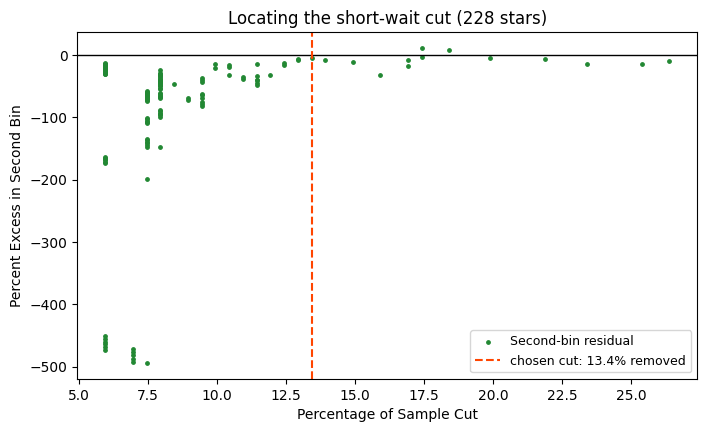

In [8]:
fig, ax = plt.subplots(figsize = (8, 4.5))
fwts.plot_cut_search(cut_results, axis = ax, title = 'Locating the short-wait cut (228 stars)')
plt.show()

## 5. Stage 3: fit the exponential and Weibull laws

```python
def fit_waiting_time_distributions(normalized_waiting_times, cut_value):
```

Returns `shape_k_all` (fit to the whole sample) and `shape_k_cut` (rate estimated only above the cut, the one to believe).

In [9]:
fit_results = fwts.fit_waiting_time_distributions(normalized_waiting_times, cut_results['cut_value'])

print(f"k (all bins)         : {fit_results['shape_k_all']:.4f}")
print(f"k (without first bin): {fit_results['shape_k_cut']:.4f}")
print(f"rate (without first bin): {fit_results['rate_lambda_cut']:.4f}")

k (all bins)         : 1.0798
k (without first bin): 1.1081
rate (without first bin): 0.8720


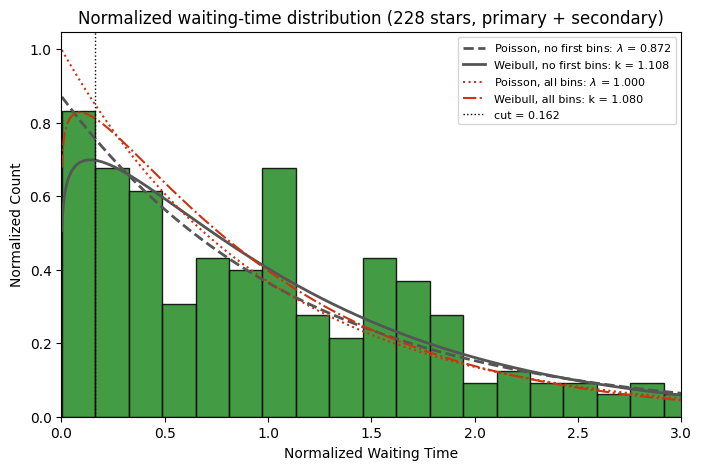

In [10]:
fig, ax = plt.subplots(figsize = (8, 5))
fwts.plot_normalized_waiting_time_distribution(
    normalized_waiting_times, fit_results, axis = ax,
    num_histogram_bins = cut_results['best_bin_count'],
    title = 'Normalized waiting-time distribution (228 stars, primary + secondary)')
plt.show()

## 6. Stage 4: bootstrap the uncertainty on `k`

The same `bootstrap_waiting_time_fits()`, with the same `bin_count_grid` passed through so every replicate's cut search uses the resolution suited to this sample size.

In [11]:
bootstrap_results = fwts.bootstrap_waiting_time_fits(
    waiting_time_results['normalized_waiting_times_unsorted'],
    bin_count_grid = np.linspace(10, 150, 141),
    num_bootstraps = 1000, random_seed = 1, verbose = True)

print()
print(bootstrap_results['shape_k_summary'])
print(f"excess at short waits: {bootstrap_results['percent_excess_short_samples'].mean():.1f}%")
print(f"excess overall       : {bootstrap_results['percent_excess_total_samples'].mean():.1f}%")

bootstrap 0% complete


bootstrap 10% complete


bootstrap 20% complete


bootstrap 30% complete


bootstrap 40% complete


bootstrap 50% complete


bootstrap 60% complete


bootstrap 70% complete


bootstrap 80% complete


bootstrap 90% complete


k = 1.1080 +/- 0.0787

k = 1.1080 +/- 0.0787
excess at short waits: -23.3%
excess overall       : -2.1%


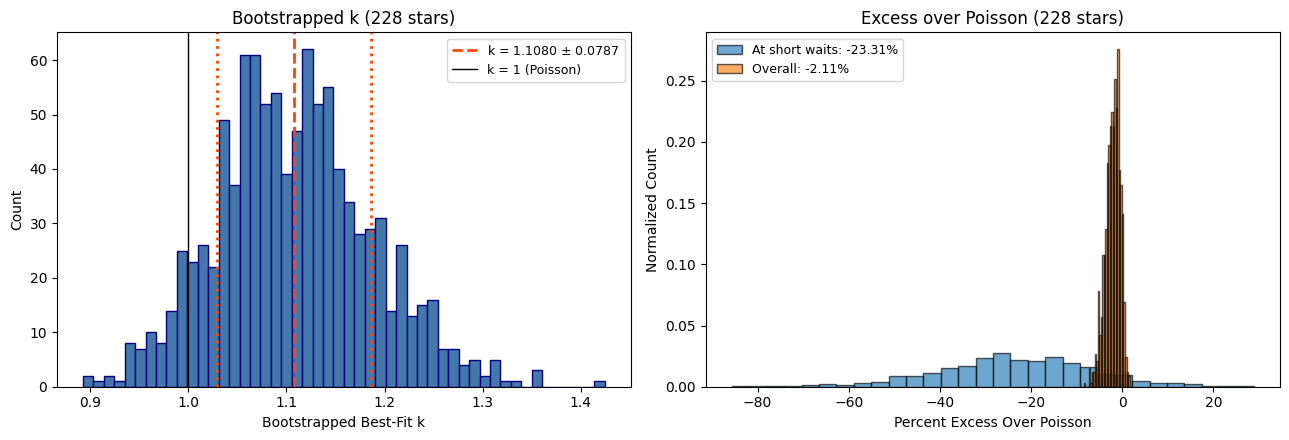

In [12]:
fig, axs = plt.subplots(1, 2, figsize = (13, 4.5))
fwts.plot_bootstrapped_shape_parameters(
    bootstrap_results['shape_k_samples'], axis = axs[0], title = 'Bootstrapped k (228 stars)')
fwts.plot_bootstrapped_percent_excess(
    bootstrap_results['percent_excess_short_samples'],
    bootstrap_results['percent_excess_total_samples'],
    axis = axs[1], title = 'Excess over Poisson (228 stars)')
plt.tight_layout()
plt.show()

`k` comes out above 1 by about 1.4 of its own bootstrapped standard deviations, which is not a significant departure from the Poisson line. A spread that wide is exactly what 201 pooled waiting times, drawn from a sample carrying only 25 secondaries, is expected to produce whether or not anything is really there. The central value happens to sit on the opposite side of 1 from sympathetic clustering, but a sample this small has very little power to make a genuine deviation emerge in either direction, so the sign of `k - 1` here carries no weight on its own. This sample uses a representative star selection, the real detection method, and the flare type the analysis is meant to measure, and it still does not have the statistics a population-level clustering measurement would need. The point here is the methodology, not a claimed discovery.

## A caveat on what this result does and doesn't show

25 secondaries out of 773 flares is still a small number to build a clustering measurement on, and 228 stars is a small slice of any real TESS survey. The module's own reference dataset pools over 10,000 flares. A significant `k` above 1 is not evidence against sympathetic flaring existing anywhere, and it is not evidence for some other regularizing mechanism either. With only 25 secondaries driving the difference from a pure-primary sample, this could just as easily be a statistical fluctuation, in which particular pairs of primaries happened to land close together in this specific draw of 228 stars, as anything real about flare timing. A proper measurement needs a much larger, still-unbiased sample before reading the direction of `k - 1` as physical, straightforward with the local-catalogue recipe above, just slower, since every additional star still needs its own `flatten`/`detect_flares` pass.

The lesson worth carrying forward is not a specific `k` value. It's this: **before pooling waiting times across stars, check how those stars were chosen.** A catalogue assembled to make good example figures elsewhere in a tutorial is not a catalogue assembled to measure a population statistic, even when every individual flare in it is entirely real and correctly detected.